In [1]:
import pymc as pm
import numpy as np
import pytensor
import pytensor.tensor as pt
from models import base_model
from priors.alpha_prior import get_d2g_alpha
from priors.transition_prior import TransitionPrior


class Model5(base_model.Model):
    def __init__(self, data=None, coords=None):
        super().__init__(data=data, coords=coords)
        self.alpha = np.ones(self.V)
        self.M = 8
        self.R = 4

    @staticmethod
    def step_fn(t, state_tm1, transition_p, end_t):
        V = transition_p.shape[0]
        idx = pt.clip(state_tm1, 0, V - 1)

        state_t = pm.Categorical.dist(p=transition_p[idx])

        end_state = pm.DiracDelta.dist(-1, shape=state_t.shape)
        state_t = pt.where(t >= end_t, end_state, state_t)

        return state_t, pm.pytensorf.collect_default_updates([state_t])

    @staticmethod
    def scan_dist(init_state, transition_p, end_t, size):
        states, _ = pytensor.scan(
            fn=Model3.step_fn,
            sequences=[pt.arange(end_t.max())],
            outputs_info=[init_state],
            non_sequences=[transition_p, end_t],
            strict=True,
        )
        return states

    def _calc_conditional_logp(self, x_tm1, x_t, mask, A, m_val, r_val):
        m_b = pt.alloc(m_val, x_tm1.shape[0], m_val.shape[0])
        r_b = pt.alloc(r_val, x_tm1.shape[0], r_val.shape[0])
        
        step_logps = pt.log(A[r_b, m_b, x_tm1, x_t])
        
        return pt.sum(step_logps * mask)

    def build_model(self, x_0_obs=None, x_t_obs=None, lengths_obs=None, m_obs=None, region_obs=None, **kwargs):
        with pm.Model() as model:
            nu = pm.Dirichlet("nu", a=np.ones(self.M))

            W_base = pm.Normal("W_base", mu=0, sigma=0.5, shape=(self.V, self.V))
            W_mode_offset = pm.Normal("W_mode_offset", mu=0, sigma=0.3, shape=(self.M, self.V, self.V))
            W_region_offset = pm.Normal("W_region_offset", mu=0, sigma=0.3, shape=(self.R, self.V, self.V))
            
            W_total = W_base + W_mode_offset[None, :, :, :] + W_region_offset[:, None, :, :]
            A = pm.Deterministic("A", pm.math.softmax(W_total, axis=-1))
            
            pi = pm.Dirichlet("pi", a=self.alpha)

            if x_t_obs is not None:
                pm.Categorical("x_0", p=pi, observed=x_0_obs)

                x_0_reshaped = pt.shape_padleft(x_0_obs)
                x_full = pt.concatenate([x_0_reshaped, x_t_obs], axis=0)
                x_tm1 = x_full[:-1]
                x_t = x_full[1:]

                t_idx = pt.arange(x_t_obs.shape[0])
                mask = t_idx[:, None] < lengths_obs[None, :]

                pm.Categorical("m", p=nu, observed=m_obs)
                
                seq_ll = self._calc_conditional_logp(x_tm1, x_t, mask, A, m_obs, region_obs)
                pm.Potential("conditional_ll", seq_ll)

            else:
                if m_obs is not None:
                    m = pm.Categorical("m", p=nu, observed=m_obs)
                else:
                    m = pm.Categorical("m", p=nu)
                    
                if region_obs is None:
                    region_obs = np.zeros(1, dtype=int)

                transition_p = pm.Deterministic("A_mr", A[region_obs, m])
                x_0 = pm.Categorical("x_0", p=pi)
                length = pm.Poisson("length", self.mean_seq_len)

                pm.CustomDist(
                    "x_t+1",
                    x_0,
                    transition_p,
                    length,
                    dist=Model3.scan_dist,
                )

        self.model = model
        return model

/Users/timeipert/PycharmProjects/generative_medieval_music_model/venvnew/lib/python3.11/site-packages/arviz/__init__.py:50: FutureWarning: 
ArviZ is undergoing a major refactor to improve flexibility and extensibility while maintaining a user-friendly interface.
Some upcoming changes may be backward incompatible.
For details and migration guidance, visit: https://python.arviz.org/en/latest/user_guide/migration_guide.html
  warn(


In [3]:
import importlib
import analysis.compare_dist_of_intv as compare
import pandas as pd

importlib.reload(compare)


def load_and_filter_data(filepath):
    df = pd.read_csv(filepath)
    df = df[["volpiano_pitches", "modus", "variant"]].dropna()
    df = df[df["modus"].isin(["1", "2", "3", "4", "5", "6", "7", "8"])]
    return df


def map_variants_to_regions(df):
    variant_map = {
        "Pa776": "west",
        "Pa903": "west",
        "Mop159": "west",
        "Zü106": "east",
        "Klo407": "east",
        "Bv34": "italy",
        "Mod7": "italy"
    }
    df["region_name"] = df["variant"].map(variant_map)
    return df


def encode_categorical_columns(df):
    df["modus"] = df["modus"].astype(int) - 1
    
    region_categories = ["west", "east", "italy"]
    df["region"] = pd.Categorical(df["region_name"], categories=region_categories).codes
    return df


def prepare_dataset(filepath):
    df = load_and_filter_data(filepath)
    df = map_variants_to_regions(df)
    
    df = df.dropna(subset=["region_name"])
    
    df = encode_categorical_columns(df)
    return df


data = prepare_dataset("data/data_gs.csv")
print(data)

                                      volpiano_pitches  modus variant  \
0    gghjhghhggkklhgfghhghkjkhkkkklhhghgkkhjggffhkj...      7   Pa776   
1    hhhghgeghghjhghghjhghkjkjkjhhjkjkjhjjhghjklkkj...      1    Bv34   
3    hgfghgegffedfghgfghgegfffehghgghhhghghgefgffdf...      3   Pa776   
4    cdddfddcddfgffffddefdcdacffefdddfddcddfgfffgff...      1  Klo407   
5    gjhhhhkhkkhgjghjhhhkhklmkjhhgjhgggfhghhfghkkhg...      1   Pa776   
..                                                 ...    ...     ...   
154  kklkhhhggggjhhgggfghhghfffhghfhghghkkkkkgfgghg...      4  Mop159   
155  ddeddffffghfddfefefddddeddfefgdedccefffdgfghgg...      1   Pa903   
156  ggfffdeccdffghkhhgghfgkjjjjhgghghjkghffhkkkjkh...      7    Bv34   
157  dffgfffffghhfgfedgffgfffhfghkklmnkkhklkkkkhkhj...      4  Klo407   
159  dfddffdfffhgfgfffdffdefgddcdfdfgfggfgjghhhghjh...      0    Bv34   

    region_name  region  
0          west       0  
1         italy       2  
3          west       0  
4          east    

In [4]:
import numpy as np
import pandas as pd
import pymc as pm
import arviz as az



def create_vocabulary(sequences):
    unique_chars = sorted(list(set("".join(sequences))))
    char_to_idx = {char: idx for idx, char in enumerate(unique_chars)}
    idx_to_char = {idx: char for char, idx in char_to_idx.items()}
    return char_to_idx, idx_to_char


def sequences_to_tensors(sequences, char_to_idx):
    N = len(sequences)
    lengths = np.array([len(seq) for seq in sequences])
    max_len = lengths.max()
    
    x_0_obs = np.zeros(N, dtype=int)
    x_t_obs = np.zeros((max_len - 1, N), dtype=int)
    
    for i, seq in enumerate(sequences):
        seq_idx = [char_to_idx[char] for char in seq]
        x_0_obs[i] = seq_idx[0]
        if len(seq_idx) > 1:
            x_t_obs[:len(seq_idx)-1, i] = seq_idx[1:]
            
    lengths_obs = lengths - 1
    return x_0_obs, x_t_obs, lengths_obs


def fit_model(df):
    sequences = df["volpiano_pitches"].values
    char_to_idx, idx_to_char = create_vocabulary(sequences)
    
    x_0_obs, x_t_obs, lengths_obs = sequences_to_tensors(sequences, char_to_idx)
    
    m_obs = df["modus"].values
    region_obs = df["region"].values
    
    model_instance = Model5()
    model_instance.V = len(char_to_idx)
    model_instance.M = 8
    model_instance.R = 3 
    
    pymc_model = model_instance.build_model(
        x_0_obs=x_0_obs,
        x_t_obs=x_t_obs,
        lengths_obs=lengths_obs,
        m_obs=m_obs,
        region_obs=region_obs
    )
    
    with pymc_model:
        idata = pm.sample(
            draws=1000,
            tune=1000,
            target_accept=0.95,
            chains=4,
            cores=4,
            return_inferencedata=True
        )
        
    return idata, char_to_idx, idx_to_char


idata, char_to_idx, idx_to_char = fit_model(data)

print("\nVocabulary mapping:")
print(char_to_idx)

summary = az.summary(idata, var_names=["nu"])
print("\nSampling Summary (nu):")
print(summary)

Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [nu, W_base, W_mode_offset, W_region_offset, pi]


Output()

Sampling 4 chains for 1_000 tune and 1_000 draw iterations (4_000 + 4_000 draws total) took 445 seconds.



Vocabulary mapping:
{'a': 0, 'b': 1, 'c': 2, 'd': 3, 'e': 4, 'f': 5, 'g': 6, 'h': 7, 'j': 8, 'k': 9, 'l': 10, 'm': 11, 'n': 12, 'o': 13, 'p': 14}

Sampling Summary (nu):
        mean     sd  hdi_3%  hdi_97%  mcse_mean  mcse_sd  ess_bulk  ess_tail  \
nu[0]  0.162  0.031   0.108    0.221        0.0    0.001    6406.0    2887.0   
nu[1]  0.162  0.031   0.107    0.220        0.0    0.001    6634.0    2874.0   
nu[2]  0.084  0.023   0.043    0.127        0.0    0.000    5836.0    2827.0   
nu[3]  0.106  0.026   0.058    0.153        0.0    0.000    6433.0    3255.0   
nu[4]  0.148  0.030   0.093    0.200        0.0    0.000    6964.0    2897.0   
nu[5]  0.098  0.025   0.054    0.144        0.0    0.000    6239.0    2675.0   
nu[6]  0.085  0.023   0.044    0.130        0.0    0.000    5903.0    2927.0   
nu[7]  0.155  0.030   0.103    0.214        0.0    0.001    3988.0    2600.0   

       r_hat  
nu[0]    1.0  
nu[1]    1.0  
nu[2]    1.0  
nu[3]    1.0  
nu[4]    1.0  
nu[5]    1.0  
nu[

{'baseline_logits': <Figure size 1200x1020 with 2 Axes>,
 'mode_offsets': <Figure size 9600x1020 with 16 Axes>,
 'region_offsets': <Figure size 3600x1020 with 6 Axes>,
 'interval_aggregates': <Figure size 1200x600 with 1 Axes>,
 'transition_matrices': <Figure size 9600x1020 with 16 Axes>,
 'mode_probabilities': <Figure size 800x400 with 1 Axes>}

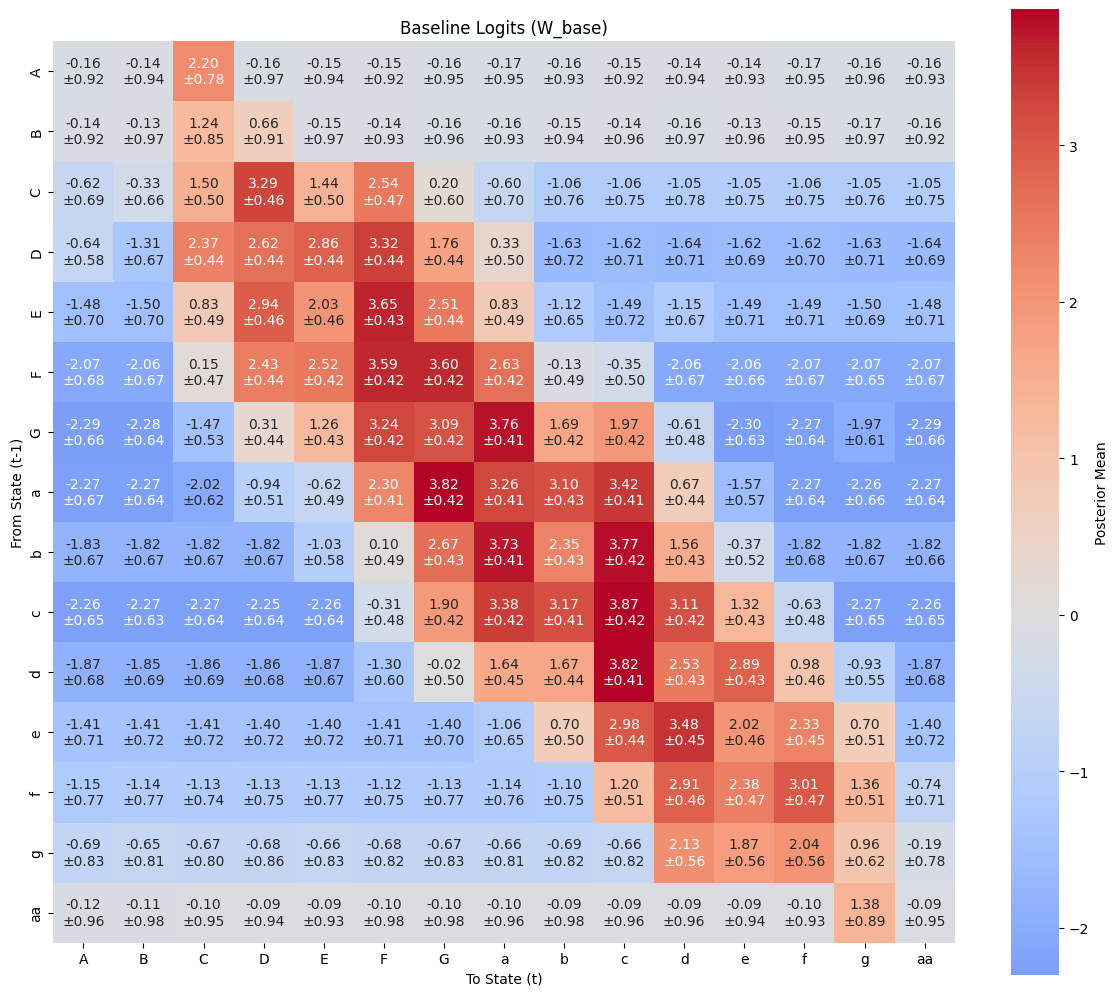

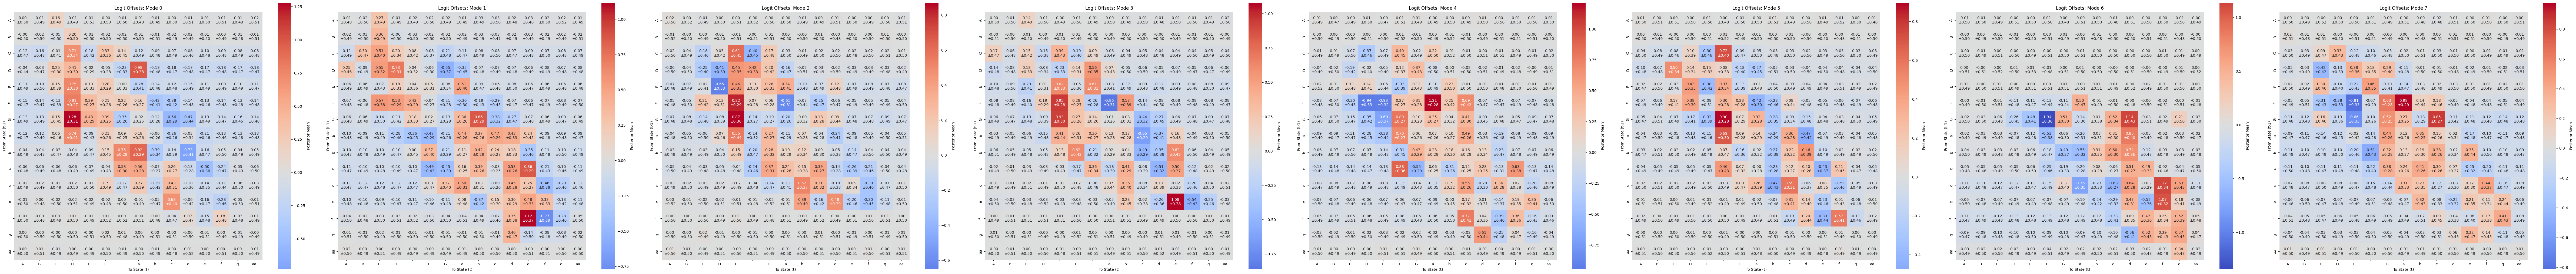

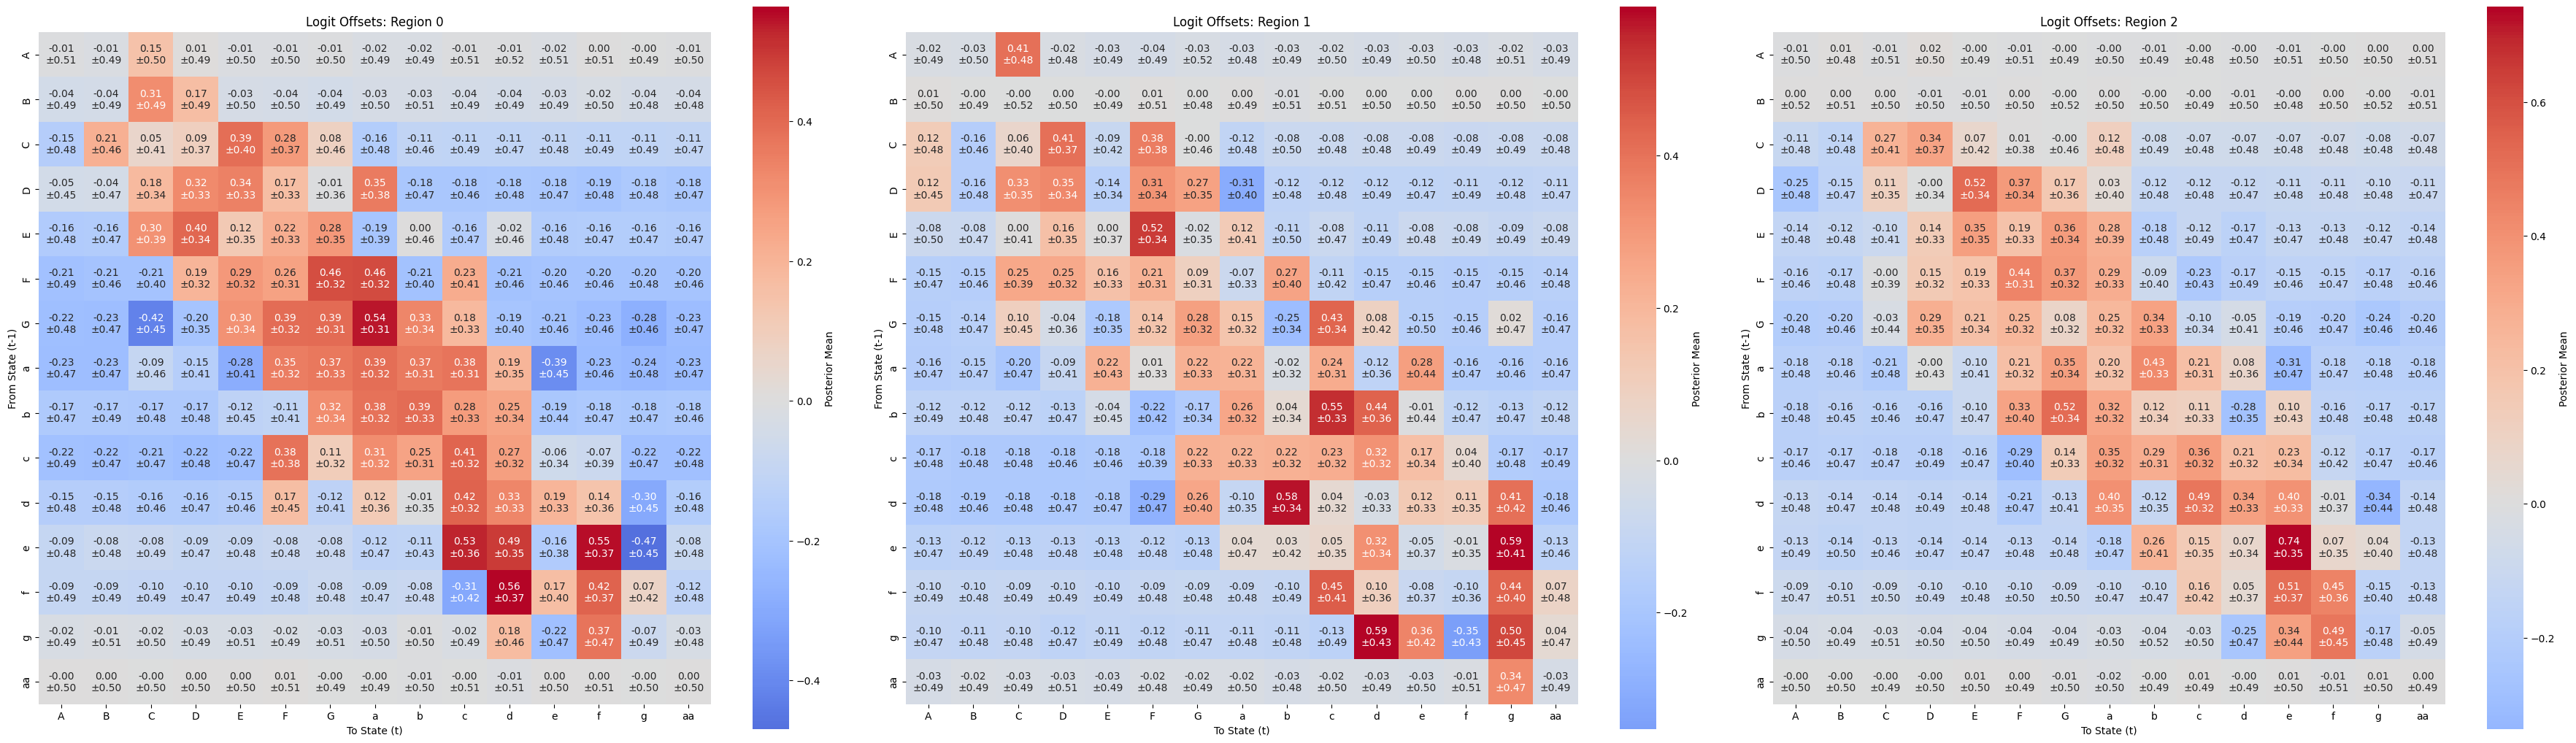

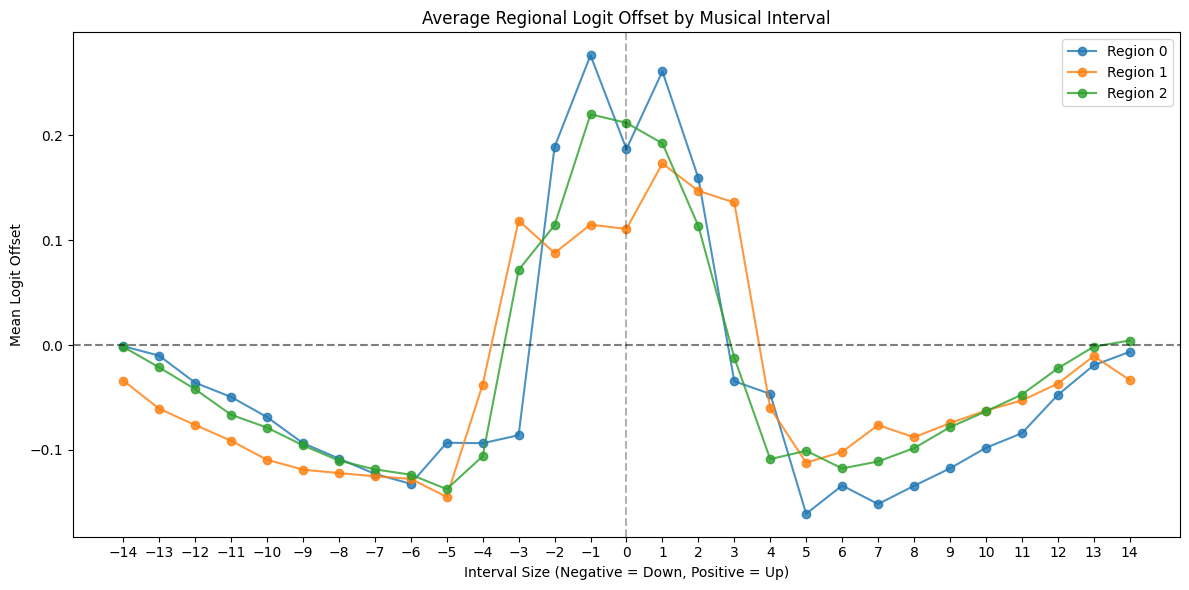

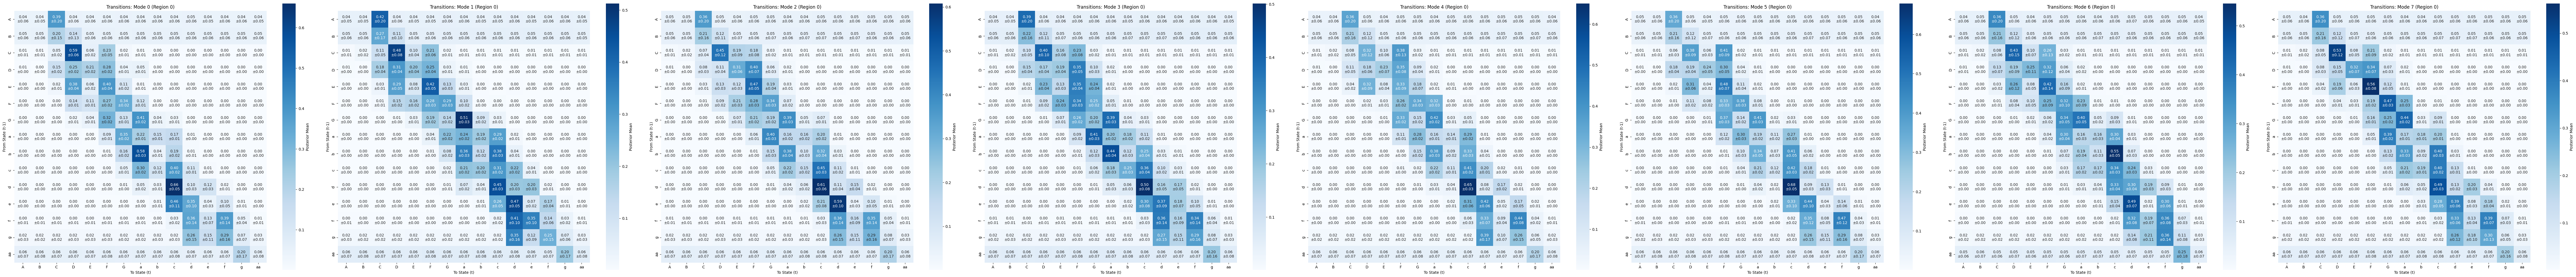

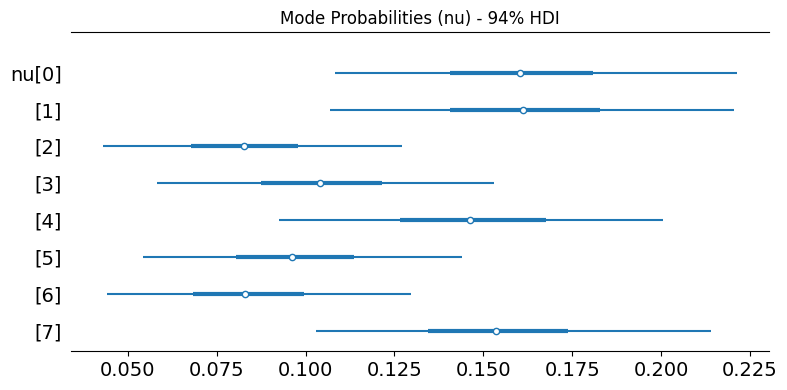

In [8]:
import arviz as az
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
from pathlib import Path

import arviz as az
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
from pathlib import Path


def _generate_pitch_labels(v_size):
    base_notes = ["A", "B", "C", "D", "E", "F", "G"]
    labels = []
    for i in range(v_size):
        octave = i // 7
        note = base_notes[i % 7]
        if octave == 0:
            labels.append(note)
        else:
            labels.append(note.lower() * octave)
    return labels


def _extract_summary_stats(idata, var_name):
    posterior = idata.posterior[var_name]
    mean_vals = posterior.mean(dim=["chain", "draw"]).values
    std_vals = posterior.std(dim=["chain", "draw"]).values
    return mean_vals, std_vals


def _create_annotation_matrix(mean_vals, std_vals):
    annot = np.empty_like(mean_vals, dtype=object)
    for i in range(mean_vals.shape[0]):
        for j in range(mean_vals.shape[1]):
            annot[i, j] = f"{mean_vals[i, j]:.2f}\n±{std_vals[i, j]:.2f}"
    return annot


def _calculate_figsize(v_size, num_plots=1):
    base_size = max(8.0, v_size * 0.8)
    return (base_size * num_plots, base_size * 0.85)


def _draw_annotated_heatmap(mean_vals, std_vals, ax, title, cmap="viridis", center=None, v_labels=None):
    annot_matrix = _create_annotation_matrix(mean_vals, std_vals)
    
    sns.heatmap(
        mean_vals,
        annot=annot_matrix,
        fmt="",
        cmap=cmap,
        ax=ax,
        center=center,
        xticklabels=v_labels if v_labels is not None else "auto",
        yticklabels=v_labels if v_labels is not None else "auto",
        cbar_kws={"label": "Posterior Mean"},
        square=True,
        annot_kws={"size": 10}
    )
    ax.set_title(title)
    ax.set_xlabel("To State (t)")
    ax.set_ylabel("From State (t-1)")


def _aggregate_by_interval(matrix, v_size):
    intervals = np.arange(-(v_size - 1), v_size)
    interval_means = np.zeros(len(intervals))
    
    for idx, interval in enumerate(intervals):
        diag_vals = np.diagonal(matrix, offset=interval)
        if len(diag_vals) > 0:
            interval_means[idx] = np.mean(diag_vals)
        else:
            interval_means[idx] = np.nan
            
    return intervals, interval_means


def plot_baseline_logits(idata, v_size):
    v_labels = _generate_pitch_labels(v_size)
    mean_vals, std_vals = _extract_summary_stats(idata, "W_base")
    
    fig, ax = plt.subplots(figsize=_calculate_figsize(v_size))
    _draw_annotated_heatmap(
        mean_vals, 
        std_vals, 
        ax, 
        title="Baseline Logits (W_base)", 
        cmap="coolwarm", 
        center=0,
        v_labels=v_labels
    )
    plt.tight_layout()
    return fig


def plot_mode_offsets(idata, v_size, m_labels=None):
    v_labels = _generate_pitch_labels(v_size)
    mean_vals, std_vals = _extract_summary_stats(idata, "W_mode_offset")
    M = mean_vals.shape[0]
    
    if m_labels is None:
        m_labels = [f"Mode {m}" for m in range(M)]
        
    fig, axes = plt.subplots(1, M, figsize=_calculate_figsize(v_size, M))
    if M == 1:
        axes = [axes]
        
    for m, ax in enumerate(axes):
        _draw_annotated_heatmap(
            mean_vals[m], 
            std_vals[m], 
            ax, 
            title=f"Logit Offsets: {m_labels[m]}", 
            cmap="coolwarm", 
            center=0,
            v_labels=v_labels
        )
        
    plt.tight_layout()
    return fig


def plot_region_offsets(idata, v_size, r_labels=None):
    v_labels = _generate_pitch_labels(v_size)
    mean_vals, std_vals = _extract_summary_stats(idata, "W_region_offset")
    R = mean_vals.shape[0]
    
    if r_labels is None:
        r_labels = [f"Region {r}" for r in range(R)]
        
    fig, axes = plt.subplots(1, R, figsize=_calculate_figsize(v_size, R))
    if R == 1:
        axes = [axes]
        
    for r, ax in enumerate(axes):
        _draw_annotated_heatmap(
            mean_vals[r], 
            std_vals[r], 
            ax, 
            title=f"Logit Offsets: {r_labels[r]}", 
            cmap="coolwarm", 
            center=0,
            v_labels=v_labels
        )
        
    plt.tight_layout()
    return fig


def plot_interval_aggregated_offsets(idata, v_size, r_labels=None):
    mean_vals, _ = _extract_summary_stats(idata, "W_region_offset")
    R = mean_vals.shape[0]
    
    if r_labels is None:
        r_labels = [f"Region {r}" for r in range(R)]
        
    fig, ax = plt.subplots(figsize=(12, 6))
    
    for r in range(R):
        intervals, interval_means = _aggregate_by_interval(mean_vals[r], v_size)
        ax.plot(intervals, interval_means, marker="o", label=r_labels[r], alpha=0.8)

    ax.set_title("Average Regional Logit Offset by Musical Interval")
    ax.set_xlabel("Interval Size (Negative = Down, Positive = Up)")
    ax.set_ylabel("Mean Logit Offset")
    
    step_size = max(1, len(intervals) // 20)
    ax.set_xticks(intervals[::step_size])
    
    ax.axhline(0, color="black", linestyle="--", alpha=0.5)
    ax.axvline(0, color="black", linestyle="--", alpha=0.3)
    ax.legend()
    plt.tight_layout()
    
    return fig


def plot_transition_matrices(idata, v_size, region_idx=0, m_labels=None, r_labels=None):
    v_labels = _generate_pitch_labels(v_size)
    mean_vals, std_vals = _extract_summary_stats(idata, "A")
    M = mean_vals.shape[1]
    
    if m_labels is None:
        m_labels = [f"Mode {m}" for m in range(M)]
        
    region_name = r_labels[region_idx] if r_labels else f"Region {region_idx}"
        
    fig, axes = plt.subplots(1, M, figsize=_calculate_figsize(v_size, M))
    if M == 1:
        axes = [axes]
        
    for m, ax in enumerate(axes):
        _draw_annotated_heatmap(
            mean_vals[region_idx, m], 
            std_vals[region_idx, m], 
            ax, 
            title=f"Transitions: {m_labels[m]} ({region_name})", 
            cmap="Blues", 
            v_labels=v_labels
        )
        
    plt.tight_layout()
    return fig


def plot_mode_probabilities(idata):
    fig, ax = plt.subplots(figsize=(8, 4))
    az.plot_forest(
        idata, 
        var_names=["nu"], 
        combined=True, 
        hdi_prob=0.94, 
        ax=ax
    )
    ax.set_title("Mode Probabilities (nu) - 94% HDI")
    plt.tight_layout()
    return fig


def plot_all_posteriors(idata, v_size, region_idx=0, m_labels=None, r_labels=None, save_dir=None):
    figs = {
        "baseline_logits": plot_baseline_logits(idata, v_size),
        "mode_offsets": plot_mode_offsets(idata, v_size, m_labels),
        "region_offsets": plot_region_offsets(idata, v_size, r_labels),
        "interval_aggregates": plot_interval_aggregated_offsets(idata, v_size, r_labels),
        "transition_matrices": plot_transition_matrices(idata, v_size, region_idx, m_labels, r_labels),
        "mode_probabilities": plot_mode_probabilities(idata)
    }
    
    if save_dir is not None:
        save_path = Path(save_dir)
        save_path.mkdir(parents=True, exist_ok=True)
        
        for name, fig in figs.items():
            file_path = save_path / f"{name}.png"
            fig.savefig(file_path, bbox_inches="tight", dpi=300)
            
    return figs

plot_all_posteriors(idata, len(char_to_idx.keys()), region_idx=0, save_dir="visual/model5_region0")